## Auto MPG
1. mpg:           continuous
2. cylinders:     multi-valued discrete
3. displacement:  continuous
4. horsepower:    continuous
5. weight:        continuous
6. acceleration:  continuous
7. model year:    multi-valued discrete
8. origin:        multi-valued discrete
9. car name:      string (unique for each instance)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/mpg.csv")
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
387,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
388,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
389,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
390,28.0,4,120.0,79,2625,18.6,82,1,ford ranger


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           392 non-null    float64
 1   cylinders     392 non-null    int64  
 2   displacement  392 non-null    float64
 3   horsepower    392 non-null    int64  
 4   weight        392 non-null    int64  
 5   acceleration  392 non-null    float64
 6   model year    392 non-null    int64  
 7   origin        392 non-null    int64  
 8   car name      392 non-null    str    
dtypes: float64(3), int64(5), str(1)
memory usage: 27.7 KB


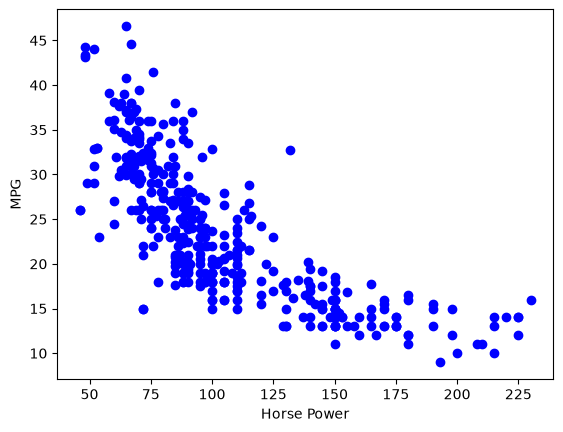

In [3]:
plt.ylabel("MPG")
plt.xlabel("Horse Power")
plt.scatter(df["horsepower"], df["mpg"], color="blue")
plt.show()

## Creación de Modelo de Regresion Lineal

In [4]:
from sklearn import linear_model


# Limpieza de datos si existen nulos
df = df.dropna()

df

# Seleccion de variables
#X = df["horsepower"].values.reshape((-1,1))
#y = df["mpg"].values.reshape((-1,1))

X = df[["horsepower"]]
y = df[["mpg"]]

In [5]:
# División en conjuntos de entrenamiento y prueba (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Instanciar y entrenar el modelo
modelo = linear_model.LinearRegression()
modelo.fit(X_train, y_train)

# Predicciones y métricas
y_pred = modelo.predict(X_test)

print("--- Parámetros del Modelo ---")
#print(f"Pendiente (coeficiente): {modelo.coef_[0]:.4f}")
#print(f"Intercepto: {modelo.intercept_:.4f}")
print("Interseccion (b)", modelo.intercept_)
print("Pendiente (m)", modelo.coef_)

print("\n--- Métricas de Evaluación ---")
print(f"Error Cuadrático Medio (MSE): {mean_squared_error(y_test, y_pred):.2f}")
print(f"Coeficiente de determinación (R²): {r2_score(y_test, y_pred):.2f}")

--- Parámetros del Modelo ---
Interseccion (b) [40.6060976]
Pendiente (m) [[-0.16259724]]

--- Métricas de Evaluación ---
Error Cuadrático Medio (MSE): 22.15
Coeficiente de determinación (R²): 0.57


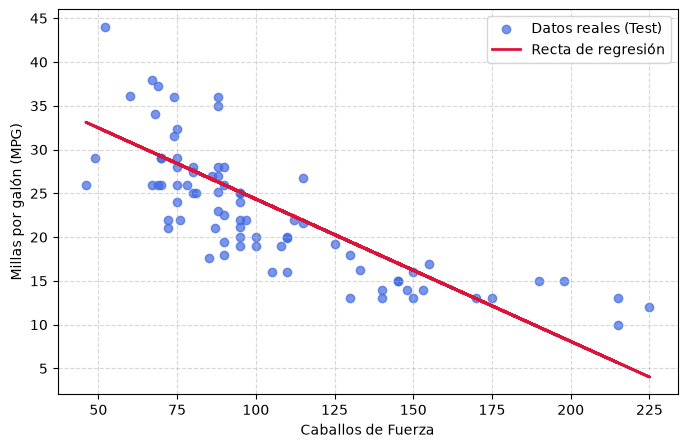

In [6]:
# Visualización didáctica
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color="royalblue", alpha=0.7, label="Datos reales (Test)")
plt.plot(X_test, y_pred, color="crimson", linewidth=2, label="Recta de regresión")
#plt.title("Regresión Lineal Simple: Peso vs. Rendimiento (MPG)")
plt.xlabel("Caballos de Fuerza")
plt.ylabel("Millas por galón (MPG)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

d:\Ciencia Datos\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
d:\Ciencia Datos\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
d:\Ciencia Datos\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


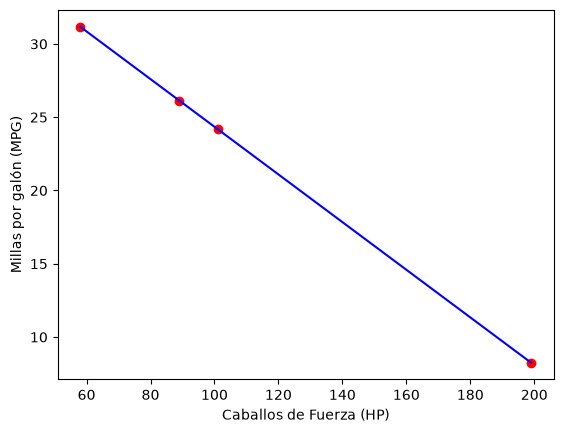

In [7]:
# realizamos pruebas con datos de muestra
entrada = [[58],[89], [101],[199]]

# Prediccion de MPG segun potencia motor
modelo.predict(entrada)


plt.scatter(entrada, modelo.predict(entrada), color="red")
plt.plot(entrada, modelo.predict(entrada), color="blue")

plt.xlabel("Caballos de Fuerza (HP)")
plt.ylabel("Millas por galón (MPG)")

plt.show()
